In [1]:
import numpy as np
from pathlib import Path
import os, sys
import matplotlib.pyplot as plt
from tqdm.notebook import tqdm
import warnings
import pandas as pd
import json

repo_root = Path("/home/thardy/elefanto/ConsciousnessTeam_Data/SOUNDMODEL/Data_SoundGOOD/LEAD_ExperimentalFolder")
os.chdir(repo_root)

if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))
os.environ["PYTHONPATH"] = str(repo_root) + os.pathsep + os.environ.get("PYTHONPATH", "")

import LEAD as lead


# Important variables
cwd = Path.cwd()
SNRs = np.array([-np.inf,-13,-11,-9,-7,-5,-3])
SubIDs = ['01','02','03','05','06','07','08','09','11','12','13','14','15','17','19','20','22','23','24','25']
colormap = {0: (0, 0, 0), 1: (0, 0.25, 1), 2: (0, 0.9375, 1), 3: (0, 0.91, 0.1), 4: (1, 0.6, 0), 5: (1, 0, 0), 6: (0.8, 0, 0)}

In [2]:
def count_sign_changes(delta_x):
    signs = np.sign(delta_x)
    sign_changes = np.sum(np.diff(signs) != 0)
    return sign_changes

def is_bifurcation(delta_x_list):
    counts = [count_sign_changes(delta_x) for delta_x in delta_x_list]
    unique_counts = set(counts)
    return len(unique_counts) > 1

def metastability_score(f, df, x_grid, tau):
    distance_to_critical = f(x_grid)**2 + df(x_grid)**2
    normalized_distance = distance_to_critical * tau**2 # between 0 (critical) and 1 (linear dynamics)
    return 1-np.min(normalized_distance) 

In [3]:
json_path = cwd / "5CV_Active_early.json"
with open(json_path, "r") as f:
    data_5cv = json.load(f)
    results_cv = data_5cv.get("results_cv")
    print("Loaded results_cv:", results_cv)

Loaded results_cv: ['NonLinear1', 'NonLinear1', 'NonLinear1', 'NonLinear1', 'NonLinear1', 'NonLinear1', 'NonLinear1', 'NonLinear1', 'GainModulation', 'GainModulation', 'NonLinear1', 'NonLinear1', 'NonLinear1', 'GainModulation', 'GainModulation', 'NonLinear1', 'GainModulation', 'NonLinear1', 'NonLinear1', 'GainModulation']


# Bifurcation Probability & Metastability Scoring 

### Via Particle Density Estimation for the best model **per participant**

Found existing summary at Fit_Active_early/MetaBifurc_AllModels_21^2/metabifurc.csv. Loading progress...
{0: 0.0, 1: 0.0, 2: 0.0, 3: 0.0, 4: 0.0, 5: 0.0, 6: 0.0, 7: 0.0, 8: 0.0, 9: 0.0, 10: 0.0, 11: 0.0, 12: 0.0, 13: 0.9933185518852672, 14: 0.999545028461824, 15: 0.0, 16: 0.0}
{0: 0.2602097107529709, 1: 0.945229043656012, 2: 0.0899606146129464, 3: 0.5689459441851009, 4: 0.8519393375233237, 5: 0.3103165350009402, 6: 0.5397715388972327, 7: 0.5607707769612461, 8: 0.9045243875686972, 9: 0.6195533999682123, 10: 5.731301792903792e-06, 11: 0.2618673048971082, 12: 0.0077590962289963, 13: 0.9999931125060666, 14: 0.9999955952144378, 15: 0.0336077295981857, 16: 0.9186322893191232}
Loaded results_cv: ['NonLinear1', 'NonLinear1', 'NonLinear1', 'NonLinear1', 'NonLinear1', 'NonLinear1', 'NonLinear1', 'NonLinear1', 'GainModulation', 'GainModulation', 'NonLinear1', 'NonLinear1', 'NonLinear1', 'GainModulation', 'GainModulation', 'NonLinear1', 'GainModulation', 'NonLinear1', 'NonLinear1', 'GainModulation

Grid Search for Part 17:   0%|          | 0/21 [00:00<?, ?it/s]

Part 17 has a 0.0000 probability of bifurcation.
Part 17 has a 0.0018 metastability score.
part 18 lets go, best model is NonLinear1
Max threshold: 1.29


Grid Search for Part 18:   0%|          | 0/21 [00:00<?, ?it/s]

Part 18 has a 0.0000 probability of bifurcation.
Part 18 has a 0.2069 metastability score.
part 19 lets go, best model is GainModulation
Max threshold: 1.24
Fitted threshold from parent model: 0.47


Tau grid for part 19:   0%|          | 0/21 [00:00<?, ?it/s]

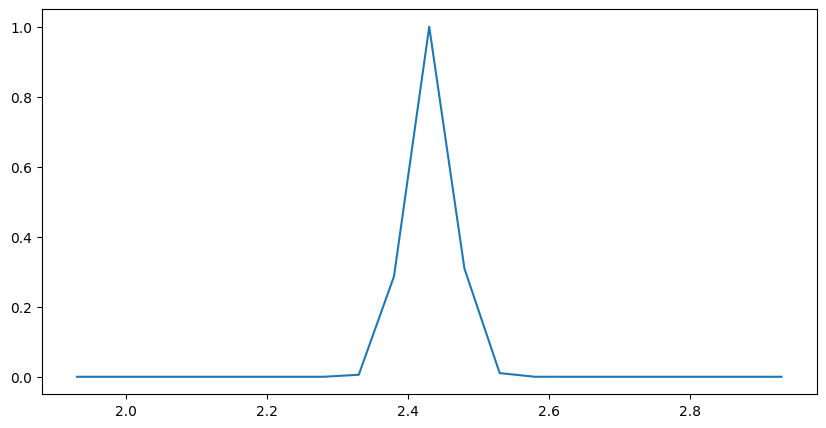

2D Search (Tau) for Part 19: 0it [00:00, ?it/s]

2.330295976433116 is a good enough tau
2.3802959764331164 is a good enough tau
2.4302959764331162 is a good enough tau
2.4802959764331165 is a good enough tau
2.5302959764331163 is a good enough tau
Part 19 has a 0.0000 probability of bifurcation.
Part 19 has a 0.9173 metastability score.


In [4]:
task = "Active"
period = "early"
file_path = Path(f'Fit_{task}_{period}')
sub_file_path = "MetaBifurc_AllModels_21^2"

# Define the summary path clearly and load existing progress 
summary_path = file_path / sub_file_path / "metabifurc.csv"
if summary_path.exists():
    print(f"Found existing summary at {summary_path}. Loading progress...")
    existing_df = pd.read_csv(summary_path, index_col=0)
    bifurcation_prob = existing_df["probability_of_bifurcation"].to_dict()
    metastability_scores = existing_df["metastability_score"].to_dict()
    print(bifurcation_prob)
    print(metastability_scores)
else:
    bifurcation_prob, metastability_scores = {}, {}

# load the name of the best model for each participant
json_path = cwd / f"5CV_{task}_{period}.json"
with open(json_path, "r") as f:
    data_5cv = json.load(f)
    results_cv = data_5cv.get("results_cv")
    print("Loaded results_cv:", results_cv)

    
for part in range(20):
    best_model = results_cv[part]
    print(f'part {part} lets go, best model is {best_model}')
    
    # --- SKIP if already processed --- 
    if part in bifurcation_prob:
        print(f">>> Part {part} already exists in CSV. Skipping...")
        continue
    
    # --- Load Data ---
    data_ref = f'myEpochs_{task}/Epoch_{SubIDs[part]}-epo.fif'
    epochs_file = cwd.parents[0] / data_ref
    
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", category=RuntimeWarning)
        state_train = lead.STG(epochs_file, tmin=100, tmax=200)
        n_categories = len(list(state_train.keys()))
        categories = list(range(n_categories))

    # --- Input Definition ---
    one_input = np.concatenate((np.zeros(60), np.ones(10), np.zeros(180)))
    input_train = {cat: np.stack([one_input for _ in range(state_train[cat].shape[0])]) for cat in categories}

    # --- Data Reformating ---
    state_train_constant_stim = {cat: state_train[cat][:,60:70] for cat in range(1, n_categories)}
    input_train_constant_stim = {cat: input_train[cat][:,60:70] for cat in range(1, n_categories)}
    no_stim_sliced = np.concatenate([state_train[0][:, i*50:(i+1)*50] for i in range(5)])
    pre_stim_sliced = np.concatenate([state_train[cat][:, :50] for cat in range(1, n_categories)])
    state_train_constant_stim[0] = np.concatenate((no_stim_sliced, pre_stim_sliced))
    input_train_constant_stim[0] = np.zeros_like(state_train_constant_stim[0])

    # --- Define upper bound for threshold parameter ---
    max_threshold = np.percentile(state_train[n_categories-1], 90)
    print(f"Max threshold: {max_threshold:.2f}")


    if best_model == 'GainModulation':

        # --- Load Parent Parameters ---
        gainmodul_parent = lead.model.StratifiedGainModulation(
            tau=10, process_noise=0.1, measure_noise=0.1, threshold=1, sharpness=5)
        param_path = file_path / f"GainModulatedModel_part{part}_params"
        gainmodul_parent.load_params(param_path)
        print(f"Fitted threshold from parent model: {gainmodul_parent.threshold:.2f}")


        # --- Define Ranges ---
        thresh_range = np.linspace(0, 2, 21)
        if gainmodul_parent.tau < 2:
            tau_range = np.linspace(1.5, 2.5, 21)
        else:
            tau_range = np.linspace(gainmodul_parent.tau - 0.5, gainmodul_parent.tau + 0.5, 21)

        
        # --- Step 1: Grid Search for Tau (to fix input params for the next step) ---
        
        ll_list_tau, params_through_tau = [], []
        for tau in tqdm(tau_range, desc=f"Tau grid for part {part}"):
            linear_resting_state = lead.model.StratifiedLinear(tau=tau, process_noise=0.1, measure_noise=0.1, w0=0)
            
            linear_resting_state.fit(
                state_series={0: state_train_constant_stim[0]},
                input_series={0: input_train_constant_stim[0]},
                init_params=[tau, 0.1, 0.1] + [0]*7,
                bounds=[(1, 25), (0.01, 1), (0.01, 1)] + [(0, 1)]*7,
                fixed_params=['tau'] + [f'w{i}' for i in range(7)])
            
            ll_list_tau.append(linear_resting_state.loglikelihood({0: state_train_constant_stim[0]}, {0: input_train_constant_stim[0]}))
            params_through_tau.append([linear_resting_state.tau, linear_resting_state.process_noise, linear_resting_state.measure_noise])

        # Plot the distrib for visual check
        ll_array_tau = np.array(ll_list_tau)
        likelihood_tau = np.exp(ll_array_tau - np.max(ll_array_tau))
        plt.figure(figsize=(10,5))
        plt.plot(tau_range, likelihood_tau)
        plt.show()


        # --- Step 2: 2D Grid Search (Tau vs Threshold) ---
        bif_array, meta_array = np.zeros((len(tau_range), len(thresh_range))), np.zeros((len(tau_range), len(thresh_range)))
        ll_array = -np.inf*np.ones((len(tau_range), len(thresh_range)))

        # We iterate through the params found in Step 1
        for idx_tau, [tau, process_noise, measure_noise] in tqdm(enumerate(params_through_tau), desc=f"2D Search (Tau) for Part {part}"):

            # When tau is too unlikely, keep the default ll = -np.inf and bif = meta = 0 (no bifurcation)
            if likelihood_tau[idx_tau] < 0.001:
                continue
            print(f'{tau} is a good enough tau')

            ll_this_tau = ll_list_tau[idx_tau]

            # Inner loop over threshold
            for idx_th, threshold in enumerate(thresh_range):

                # When threshold is too high compared to data, keep the default ll = -np.inf and bif = meta = 0
                if threshold > max_threshold:
                    continue
                
                # A. Fit gain and input_weight for this specific (tau, threshold) combo
                ll_local = 0
                # Initialize base model for this grid point
                gainmodul = lead.model.StratifiedGainModulation(
                    tau=tau, process_noise=process_noise, measure_noise=measure_noise, 
                    threshold=threshold, sharpness=5)
                
                for cat in range(1, n_categories):
                    # Retrieve parent weights
                    w_parent = getattr(gainmodul_parent, f'w{cat}')
                    g_parent = getattr(gainmodul_parent, f'g{cat}')
                    
                    gainmodul_one_cat = lead.model.GainModulation(
                        tau=tau, process_noise=process_noise, measure_noise=measure_noise, 
                        threshold=threshold, sharpness=5, 
                        input_weight=w_parent, gain=g_parent)
                    
                    # Fit specific category
                    gainmodul_one_cat.fit(
                        state_series={0: state_train_constant_stim[cat]},
                        input_series={0: input_train_constant_stim[cat]},
                        init_params=[getattr(gainmodul_one_cat, pname) for pname in gainmodul_one_cat._param_names],
                        bounds=[(1,25), (0.01, 1), (0.01, 1), (0, 1), (0, 1), (0, 2), (0, 10)],
                        fixed_params=['tau', 'process_noise', 'measure_noise', 'threshold', 'sharpness'])
                    
                    ll_local += gainmodul_one_cat.loglikelihood({0: state_train_constant_stim[cat]}, {0: input_train_constant_stim[cat]})
                    
                    # Update the main stratified model with fitted params
                    gainmodul.set_params({f'w{cat}': gainmodul_one_cat.input_weight, f'g{cat}': gainmodul_one_cat.gain})
                
                ll_array[idx_tau, idx_th] = ll_this_tau + ll_local
                
                # B. Assess bifurcation and metastability (Linear Interpolation)
                states = np.linspace(-0.5, 3, 1000)
                delta_x_list = []
                max_metascore = 0
                
                for cat in range(n_categories - 1):
                    # Initial state diff
                    delta_x_list.append(gainmodul.core(state=states, input_value=1, signal_category=cat) - states)
                    
                    w1, g1 = getattr(gainmodul, f'w{cat}'), getattr(gainmodul, f'g{cat}')
                    w2, g2 = getattr(gainmodul, f'w{cat+1}'), getattr(gainmodul, f'g{cat+1}')
                    
                    # Travel on the (w1, g1) -> (w2, g2) segment 
                    for t in np.linspace(0, 1, 100):
                        w, g = w1 + t*(w2-w1), g1 + t*(g2-g1)
                        
                        interp_model = lead.model.GainModulation(
                            tau=tau, process_noise=process_noise, measure_noise=measure_noise, 
                            threshold=threshold, sharpness=5, 
                            input_weight=w, gain=g
                        )

                        # Prepare for metastability score calculation
                        model_func = interp_model.core
                        def f(states, input_value=0, signal_category=cat):
                            return model_func(states, input_value * np.ones_like(states), signal_category) - states
                        def df(states, input_value=0, signal_category=cat):
                            epsilon = 1e-5
                            return (f(states + epsilon, input_value, signal_category) - f(states - epsilon, input_value, signal_category)) / (2*epsilon)
            
                        # Compute metastability score
                        metascore = metastability_score(lambda x: f(x, input_value=1, signal_category=cat), 
                                                        lambda x: df(x, input_value=1, signal_category=cat), 
                                                        states, tau=tau)
                        max_metascore = max(max_metascore, metascore)

                        # Prepare for bifurcation check
                        delta_x_list.append(interp_model.core(state=states, input_value=1, signal_category=0) - states)

                # Compute bifurcation check
                bifbool = is_bifurcation(delta_x_list)
                bif_array[idx_tau, idx_th] = int(bifbool)
                meta_array[idx_tau, idx_th] = max_metascore

    if best_model == 'NonLinear1':

        # --- Load Parent Parameters ---
        gainfixed_parent = lead.model.StratifiedNonLinear1(
            tau=10, process_noise=0.1, measure_noise=0.1, threshold=1, sharpness=5, gain=0)
        param_path = file_path / f"GainFixedModel_part{part}_params"
        gainfixed_parent.load_params(param_path)

        # --- Define Ranges ---
        thresh_range = np.linspace(0, 2, 21)
        if gainfixed_parent.tau < 2:
            tau_range = np.linspace(1.5, 2.5, 21)
        else:
            tau_range = np.linspace(gainfixed_parent.tau - 0.5, gainfixed_parent.tau + 0.5, 21)

        # --- Grid Search for Tau & threshold at the same time (model StratifiedNonLinear1) ---
        bif_array, meta_array = np.zeros((len(tau_range), len(thresh_range))), np.zeros((len(tau_range), len(thresh_range)))
        ll_array = -np.inf*np.ones((len(tau_range), len(thresh_range)))

        for idx_tau, tau in tqdm(enumerate(tau_range), total=len(tau_range), desc=f"Grid Search for Part {part}"):
            for idx_th, threshold in enumerate(thresh_range):

                # When threshold is too high compared to data, keep the default ll = -np.inf and bif = meta = 0
                if threshold > max_threshold:
                    continue

                # --- Define Model Instance ---
                gainfixed = lead.model.StratifiedNonLinear1(
                    tau=tau, 
                    process_noise=gainfixed_parent.process_noise, 
                    measure_noise=gainfixed_parent.measure_noise, 
                    threshold=threshold, 
                    gain=gainfixed_parent.gain,
                    sharpness=5
                )
                gainfixed.set_params({f'w{cat}': getattr(gainfixed_parent, f'w{cat}') for cat in range(1, n_categories)})

                # A. Fit Relevant Parameters (strategy like lead.fitting_tools)
                for k_loop in range(2):
                    
                    # refine gain first
                    gainfixed.fit(
                        state_series=state_train_constant_stim,
                        input_series=input_train_constant_stim,
                        init_params=[getattr(gainfixed, pname) for pname in gainfixed._param_names],
                        bounds=[(1,25), (0.01, 1), (0.01, 1)] + [(0, 1)]*7 + [(0, 0.5), (0, 2), (0, 10)],
                        fixed_params=['tau', 'process_noise', 'measure_noise', 'threshold', 'sharpness'] + [f'w{cat}' for cat in range(1, n_categories)])
                    
                    # refine the input weights
                    for cat in range(1, n_categories):
                        
                        gainfixed_one_cat = lead.model.NonLinear1(
                            tau=gainfixed.tau, 
                            process_noise=gainfixed.process_noise, 
                            measure_noise=gainfixed.measure_noise,
                            input_weight=getattr(gainfixed, f'w{cat}'),
                            gain=gainfixed.gain,
                            threshold=gainfixed.threshold, 
                            sharpness=5
                        )
                        
                        gainfixed_one_cat.fit(
                            state_series={0: state_train_constant_stim[cat]},
                            input_series={0: input_train_constant_stim[cat]},
                            init_params=[getattr(gainfixed_one_cat, pname) for pname in gainfixed_one_cat._param_names],
                            bounds=[(1,25), (0.01, 1), (0.01, 1), (0, 1), (0, 1), (0, 2), (0, 10)],
                            fixed_params=['tau', 'process_noise', 'measure_noise', 'threshold', 'gain', 'sharpness'],
                            feedback=False
                        )
                        gainfixed.set_params({f'w{cat}': gainfixed_one_cat.input_weight})

                ll_array[idx_tau, idx_th] = gainfixed.loglikelihood(state_train_constant_stim, input_train_constant_stim)


                # B. Assess bifurcation and metastability (Linear Interpolation)
                states = np.linspace(-0.5, 3, 1000)
                delta_x_list = []
                max_metascore = 0
                
                for cat in range(n_categories - 1):
                    # Initial state diff
                    delta_x_list.append(gainfixed.core(state=states, input_value=1, signal_category=cat) - states)
                    
                    w1, w2 = getattr(gainfixed, f'w{cat}'), getattr(gainfixed, f'w{cat+1}')
                    
                    # Travel on the w1 -> w2 segment
                    for t in np.linspace(0, 1, 100):
                        w = w1 + t*(w2-w1)
                        
                        interp_model = lead.model.NonLinear1(
                            tau=gainfixed.tau, 
                            process_noise=gainfixed.process_noise, 
                            measure_noise=gainfixed.measure_noise, 
                            threshold=gainfixed.threshold, 
                            sharpness=gainfixed.sharpness, 
                            input_weight=w, 
                            gain=gainfixed.gain
                        )
                        # Prepare for metastability score calculation
                        model_func = interp_model.core
                        def f(states, input_value=0, signal_category=cat):
                            return model_func(states, input_value * np.ones_like(states), signal_category) - states
                        def df(states, input_value=0, signal_category=cat):
                            epsilon = 1e-5
                            return (f(states + epsilon, input_value, signal_category) - f(states - epsilon, input_value, signal_category)) / (2*epsilon)
            
                        # Compute metastability score
                        metascore = metastability_score(lambda x: f(x, input_value=1, signal_category=cat), 
                                                        lambda x: df(x, input_value=1, signal_category=cat), 
                                                        states, tau=tau)
                        max_metascore = max(max_metascore, metascore)

                        # Prepare for bifurcation check
                        delta_x_list.append(interp_model.core(state=states, input_value=1, signal_category=0) - states)

                # Compute bifurcation check
                bifbool = is_bifurcation(delta_x_list)
                bif_array[idx_tau, idx_th] = int(bifbool)
                meta_array[idx_tau, idx_th] = max_metascore


    if best_model == 'Linear':
        bif_array, meta_array = np.zeros((20, 20)), np.zeros((20, 20))
        ll_array = -np.ones((20, 20))


    # --- Process Results ---
    likelihood = np.exp(ll_array - np.max(ll_array))

    # Save Results
    os.makedirs(file_path / sub_file_path, exist_ok=True)
    np.savez(file_path / sub_file_path / f"2D_grid_search_part{part}.npz", threshold_range=thresh_range, tau_range=tau_range, ll=ll_array, likelihood=likelihood, bifbool=bif_array, metascore=meta_array)

    # Weighting BifProb and MetaScore over the 2D surface)
    bifprob = np.average(bif_array, weights=likelihood)
    metascore = np.average(meta_array, weights=likelihood)
    bifurcation_prob[part], metastability_scores[part] = bifprob, metascore
    print(f'Part {part} has a {bifprob:.4f} probability of bifurcation.')
    print(f'Part {part} has a {metascore:.4f} metastability score.')

    # Save summary CSV
    df_bifprob = pd.DataFrame.from_dict(
        bifurcation_prob, orient="index", columns=["probability_of_bifurcation"]
    ).sort_index()
    df_metascore = pd.DataFrame.from_dict(
        metastability_scores, orient="index", columns=["metastability_score"]
    ).sort_index()
    df = pd.concat([df_bifprob, df_metascore], axis=1)
    df.to_csv(file_path / sub_file_path / "metabifurc.csv")

    # --- 3. Plotting (2D Heatmap with Contours) ---
    plt.figure(figsize=(10, 8))
    
    # Create 2D Meshgrid for plotting
    # thresh_range (x-axis), tau_range (y-axis)
    X, Y = np.meshgrid(thresh_range, tau_range)
    
    # 1. Plot Heatmap of Likelihood
    # Using pcolormesh for the heatmap
    pcm = plt.pcolormesh(X, Y, likelihood, shading='auto', cmap='viridis')
    plt.colorbar(pcm, label='Relative Likelihood')
    
    # 2. Plot Contour of Bifurcation Boundary
    # We draw a line at 0.5 (since bif_array is 0 or 1) to show the border
    # colors='red' makes the bifurcation line distinct
    if np.any(bif_array) and not np.all(bif_array):
        CS = plt.contour(X, Y, bif_array, levels=[0.5], colors='red', linewidths=2)
        # Create a proxy artist for the legend
        from matplotlib.lines import Line2D
        proxy_line = Line2D([0], [0], color='red', linewidth=2, label='Bifurcation Boundary')
        plt.legend(handles=[proxy_line], loc='upper right')
    elif np.all(bif_array):
        plt.title(f"Part {part} (All Bifurcation)")
    else:
        plt.title(f"Part {part} (No Bifurcation)")

    plt.title(f'Parameter Space: Tau vs Threshold - Part {part}\nWeighted Bifurcation Prob: {bifprob:.3f}')
    plt.xlabel('Threshold')
    plt.ylabel('Tau')
    
    # Save plot
    plt.savefig(file_path / sub_file_path / f"2D_likelihood_part{part}_{task}.png")
    plt.close()

### Via Particle Density Estimation for the Modulated Gain model

Loaded results_cv: ['NonLinear1', 'NonLinear1', 'NonLinear1', 'NonLinear1', 'NonLinear1', 'NonLinear1', 'NonLinear1', 'NonLinear1', 'GainModulation', 'GainModulation', 'NonLinear1', 'NonLinear1', 'NonLinear1', 'GainModulation', 'GainModulation', 'NonLinear1', 'GainModulation', 'NonLinear1', 'NonLinear1', 'GainModulation']
part 0 lets go, best model is NonLinear1, but we'll do ModulatedGain anyway


/home/thardy/soundmodelenv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/thardy/soundmodelenv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/thardy/soundmodelenv/lib/pyt

Max threshold: 1.22
Fitted threshold from parent model: 0.48


Tau grid for part 0:   0%|          | 0/21 [00:00<?, ?it/s]

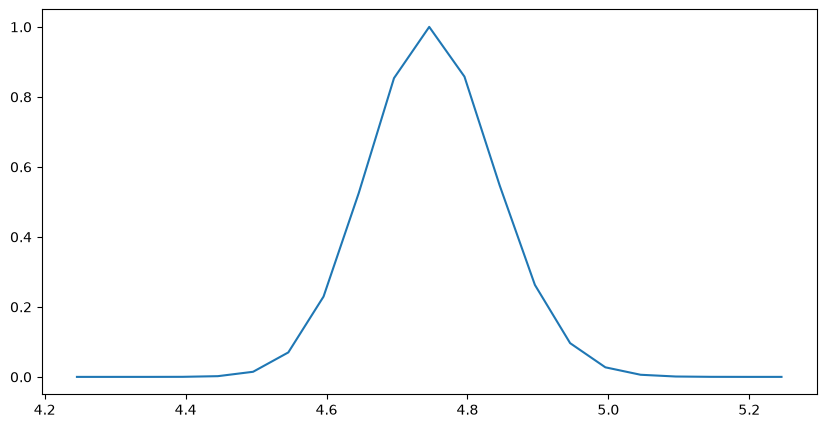

2D Search (Tau) for Part 0: 0it [00:00, ?it/s]

4.445743306000877 is a good enough tau
4.495743306000877 is a good enough tau
4.545743306000877 is a good enough tau
4.595743306000877 is a good enough tau
4.6457433060008775 is a good enough tau
4.695743306000877 is a good enough tau
4.745743306000877 is a good enough tau
4.795743306000877 is a good enough tau
4.845743306000877 is a good enough tau
4.8957433060008775 is a good enough tau
4.945743306000877 is a good enough tau
4.995743306000877 is a good enough tau
5.045743306000877 is a good enough tau
5.095743306000877 is a good enough tau
Part 0 has a 0.0000 probability of bifurcation.
Part 0 has a 0.8344 metastability score.
part 1 lets go, best model is NonLinear1, but we'll do ModulatedGain anyway


/home/thardy/soundmodelenv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/thardy/soundmodelenv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/thardy/soundmodelenv/lib/pyt

Max threshold: 1.34
Fitted threshold from parent model: 1.49


Tau grid for part 1:   0%|          | 0/21 [00:00<?, ?it/s]

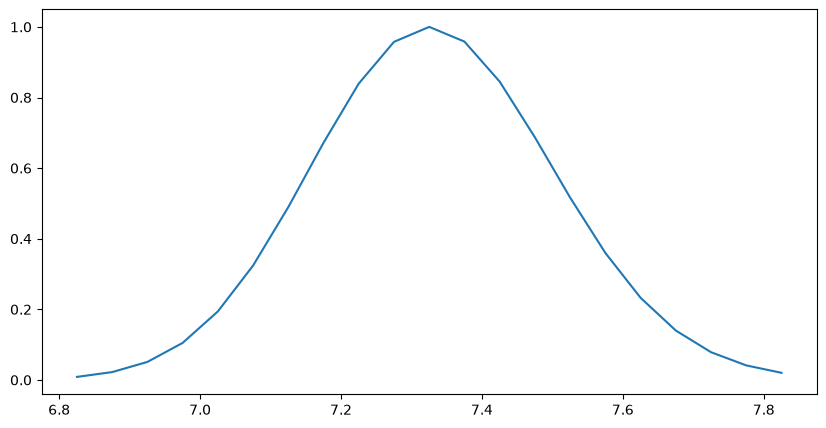

2D Search (Tau) for Part 1: 0it [00:00, ?it/s]

6.825215981544778 is a good enough tau
6.875215981544778 is a good enough tau
6.925215981544778 is a good enough tau
6.975215981544778 is a good enough tau
7.025215981544778 is a good enough tau
7.075215981544778 is a good enough tau
7.125215981544778 is a good enough tau
7.175215981544778 is a good enough tau
7.225215981544778 is a good enough tau
7.275215981544778 is a good enough tau
7.325215981544778 is a good enough tau
7.375215981544778 is a good enough tau
7.425215981544778 is a good enough tau
7.475215981544778 is a good enough tau
7.525215981544778 is a good enough tau
7.575215981544778 is a good enough tau
7.625215981544778 is a good enough tau
7.675215981544778 is a good enough tau
7.725215981544778 is a good enough tau
7.775215981544778 is a good enough tau
7.825215981544778 is a good enough tau
Part 1 has a 0.1457 probability of bifurcation.
Part 1 has a 0.9942 metastability score.
part 2 lets go, best model is NonLinear1, but we'll do ModulatedGain anyway


/home/thardy/soundmodelenv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/thardy/soundmodelenv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/thardy/soundmodelenv/lib/pyt

Max threshold: 1.29
Fitted threshold from parent model: 0.94


Tau grid for part 2:   0%|          | 0/21 [00:00<?, ?it/s]

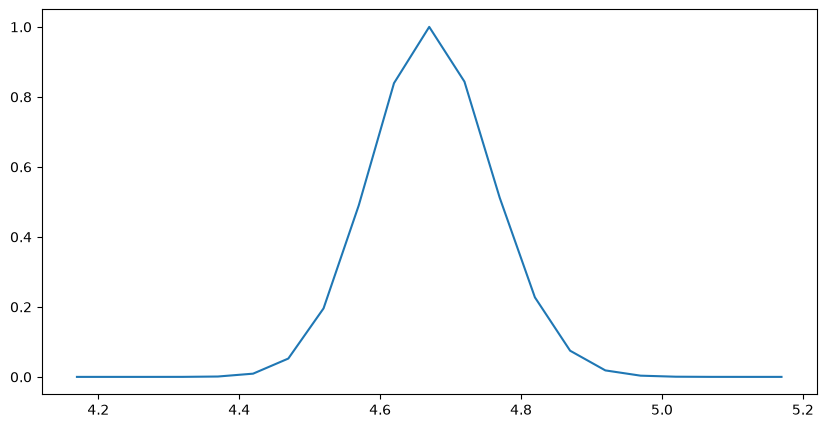

2D Search (Tau) for Part 2: 0it [00:00, ?it/s]

4.369686390598381 is a good enough tau
4.419686390598381 is a good enough tau
4.469686390598381 is a good enough tau
4.51968639059838 is a good enough tau
4.569686390598381 is a good enough tau
4.619686390598381 is a good enough tau
4.669686390598381 is a good enough tau
4.719686390598381 is a good enough tau
4.76968639059838 is a good enough tau
4.819686390598381 is a good enough tau
4.869686390598381 is a good enough tau
4.919686390598381 is a good enough tau
4.969686390598381 is a good enough tau
Part 2 has a 0.0000 probability of bifurcation.
Part 2 has a 0.8561 metastability score.
part 3 lets go, best model is NonLinear1, but we'll do ModulatedGain anyway


/home/thardy/soundmodelenv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/thardy/soundmodelenv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/thardy/soundmodelenv/lib/pyt

Max threshold: 1.27
Fitted threshold from parent model: 0.00


Tau grid for part 3:   0%|          | 0/21 [00:00<?, ?it/s]

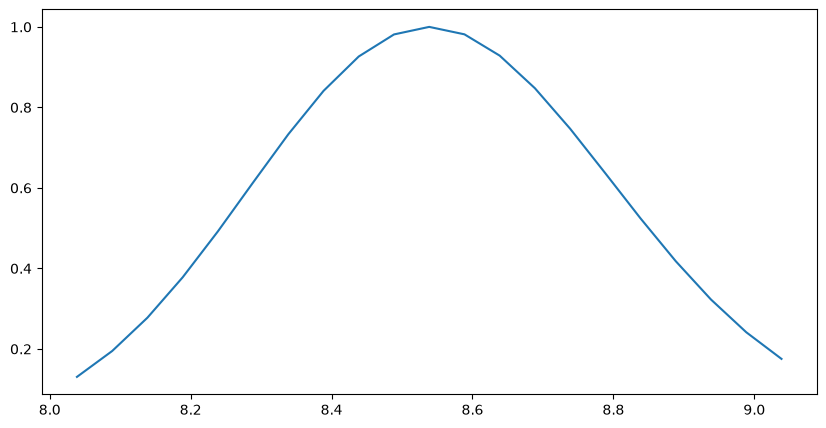

2D Search (Tau) for Part 3: 0it [00:00, ?it/s]

8.038589242943623 is a good enough tau
8.088589242943623 is a good enough tau
8.138589242943622 is a good enough tau
8.188589242943623 is a good enough tau
8.238589242943622 is a good enough tau
8.288589242943623 is a good enough tau
8.338589242943623 is a good enough tau
8.388589242943622 is a good enough tau
8.438589242943623 is a good enough tau
8.488589242943622 is a good enough tau
8.538589242943623 is a good enough tau
8.588589242943623 is a good enough tau
8.638589242943622 is a good enough tau
8.688589242943623 is a good enough tau
8.738589242943622 is a good enough tau
8.788589242943623 is a good enough tau
8.838589242943623 is a good enough tau
8.888589242943622 is a good enough tau
8.938589242943623 is a good enough tau
8.988589242943622 is a good enough tau
9.038589242943623 is a good enough tau
Part 3 has a 0.0000 probability of bifurcation.
Part 3 has a 0.3105 metastability score.
part 4 lets go, best model is NonLinear1, but we'll do ModulatedGain anyway


/home/thardy/soundmodelenv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/thardy/soundmodelenv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/thardy/soundmodelenv/lib/pyt

Max threshold: 1.16
Fitted threshold from parent model: 2.00


Tau grid for part 4:   0%|          | 0/21 [00:00<?, ?it/s]

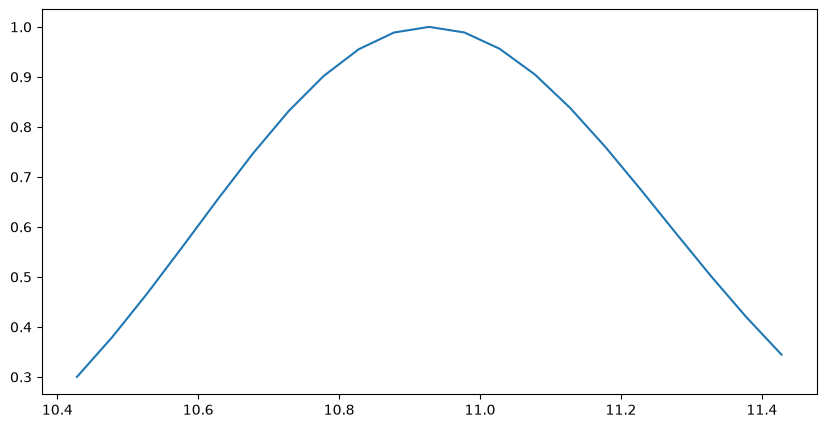

2D Search (Tau) for Part 4: 0it [00:00, ?it/s]

10.427878226222695 is a good enough tau
10.477878226222696 is a good enough tau
10.527878226222695 is a good enough tau
10.577878226222696 is a good enough tau
10.627878226222695 is a good enough tau
10.677878226222695 is a good enough tau
10.727878226222696 is a good enough tau
10.777878226222695 is a good enough tau
10.827878226222696 is a good enough tau
10.877878226222695 is a good enough tau
10.927878226222695 is a good enough tau
10.977878226222696 is a good enough tau
11.027878226222695 is a good enough tau
11.077878226222696 is a good enough tau
11.127878226222695 is a good enough tau
11.177878226222695 is a good enough tau
11.227878226222696 is a good enough tau
11.277878226222695 is a good enough tau
11.327878226222696 is a good enough tau
11.377878226222695 is a good enough tau
11.427878226222695 is a good enough tau
Part 4 has a 0.0000 probability of bifurcation.
Part 4 has a 0.4416 metastability score.
part 5 lets go, best model is NonLinear1, but we'll do ModulatedGain an

/home/thardy/soundmodelenv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/thardy/soundmodelenv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/thardy/soundmodelenv/lib/pyt

Max threshold: 1.24
Fitted threshold from parent model: 1.03


Tau grid for part 5:   0%|          | 0/21 [00:00<?, ?it/s]

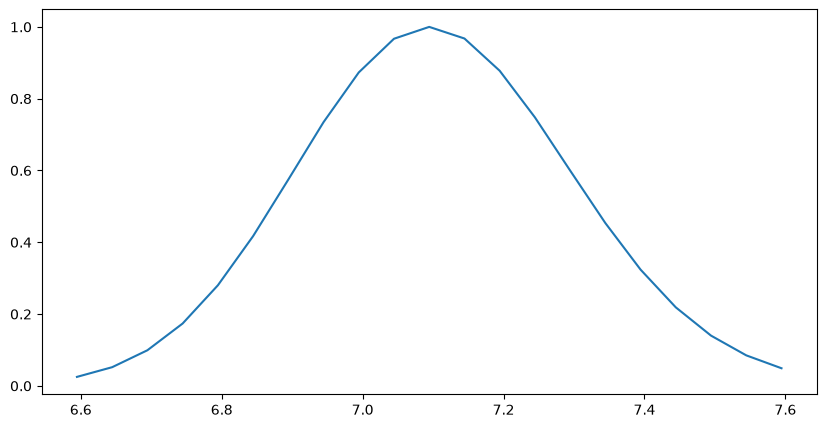

2D Search (Tau) for Part 5: 0it [00:00, ?it/s]

6.594487115212348 is a good enough tau
6.644487115212348 is a good enough tau
6.694487115212348 is a good enough tau
6.7444871152123484 is a good enough tau
6.794487115212348 is a good enough tau
6.844487115212348 is a good enough tau
6.894487115212348 is a good enough tau
6.944487115212348 is a good enough tau
6.9944871152123484 is a good enough tau
7.044487115212348 is a good enough tau
7.094487115212348 is a good enough tau
7.144487115212348 is a good enough tau
7.194487115212349 is a good enough tau
7.2444871152123484 is a good enough tau
7.294487115212348 is a good enough tau
7.344487115212348 is a good enough tau
7.394487115212348 is a good enough tau
7.444487115212349 is a good enough tau
7.4944871152123484 is a good enough tau
7.544487115212348 is a good enough tau
7.594487115212348 is a good enough tau
Part 5 has a 0.0000 probability of bifurcation.
Part 5 has a 0.9455 metastability score.
part 6 lets go, best model is NonLinear1, but we'll do ModulatedGain anyway


/home/thardy/soundmodelenv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/thardy/soundmodelenv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/thardy/soundmodelenv/lib/pyt

Max threshold: 1.20
Fitted threshold from parent model: 0.42


Tau grid for part 6:   0%|          | 0/21 [00:00<?, ?it/s]

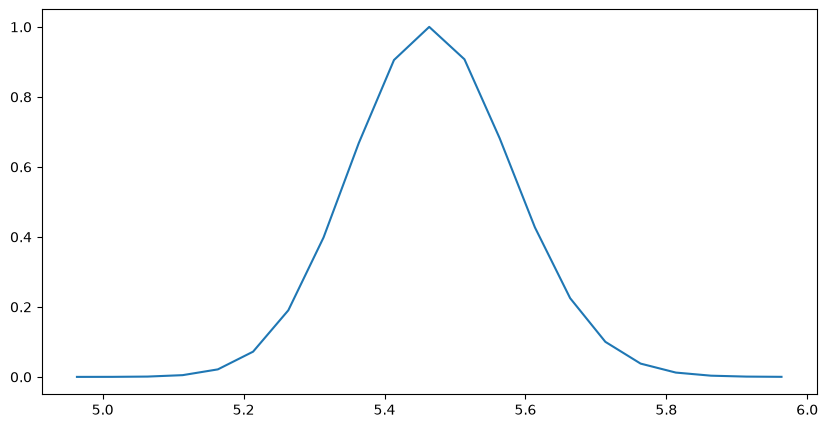

2D Search (Tau) for Part 6: 0it [00:00, ?it/s]

5.113468661818531 is a good enough tau
5.163468661818531 is a good enough tau
5.21346866181853 is a good enough tau
5.26346866181853 is a good enough tau
5.31346866181853 is a good enough tau
5.363468661818531 is a good enough tau
5.413468661818531 is a good enough tau
5.46346866181853 is a good enough tau
5.51346866181853 is a good enough tau
5.563468661818531 is a good enough tau
5.613468661818531 is a good enough tau
5.663468661818531 is a good enough tau
5.71346866181853 is a good enough tau
5.76346866181853 is a good enough tau
5.813468661818531 is a good enough tau
5.863468661818531 is a good enough tau
Part 6 has a 0.3868 probability of bifurcation.
Part 6 has a 0.9885 metastability score.
part 7 lets go, best model is NonLinear1, but we'll do ModulatedGain anyway


/home/thardy/soundmodelenv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/thardy/soundmodelenv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/thardy/soundmodelenv/lib/pyt

Max threshold: 1.22
Fitted threshold from parent model: 0.20


Tau grid for part 7:   0%|          | 0/21 [00:00<?, ?it/s]

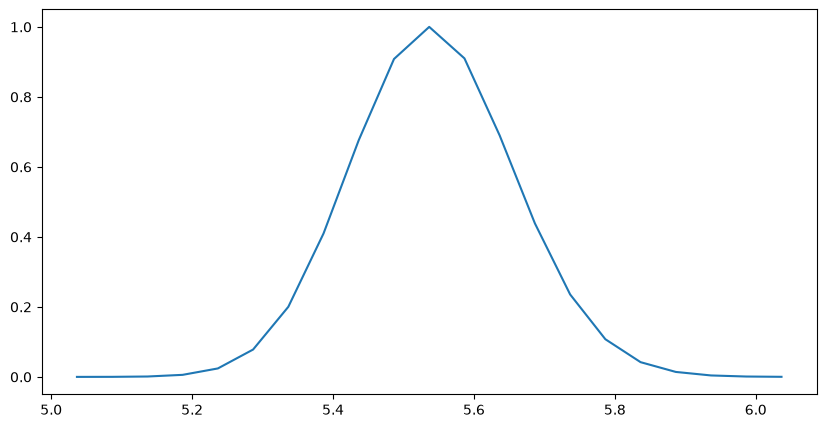

2D Search (Tau) for Part 7: 0it [00:00, ?it/s]

5.1365364726520095 is a good enough tau
5.18653647265201 is a good enough tau
5.23653647265201 is a good enough tau
5.28653647265201 is a good enough tau
5.33653647265201 is a good enough tau
5.3865364726520095 is a good enough tau
5.43653647265201 is a good enough tau
5.48653647265201 is a good enough tau
5.53653647265201 is a good enough tau
5.58653647265201 is a good enough tau
5.6365364726520095 is a good enough tau
5.68653647265201 is a good enough tau
5.73653647265201 is a good enough tau
5.78653647265201 is a good enough tau
5.83653647265201 is a good enough tau
5.8865364726520095 is a good enough tau
5.93653647265201 is a good enough tau
5.98653647265201 is a good enough tau
Part 7 has a 0.0037 probability of bifurcation.
Part 7 has a 0.7751 metastability score.
part 8 lets go, best model is GainModulation, but we'll do ModulatedGain anyway


/home/thardy/soundmodelenv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/thardy/soundmodelenv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/thardy/soundmodelenv/lib/pyt

Max threshold: 1.36
Fitted threshold from parent model: 2.00


Tau grid for part 8:   0%|          | 0/21 [00:00<?, ?it/s]

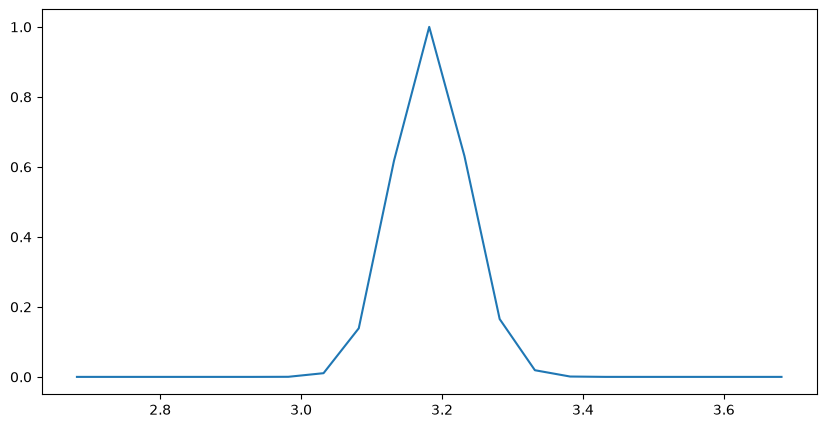

2D Search (Tau) for Part 8: 0it [00:00, ?it/s]

3.0318559902953224 is a good enough tau
3.081855990295322 is a good enough tau
3.1318559902953225 is a good enough tau
3.1818559902953223 is a good enough tau
3.2318559902953226 is a good enough tau
3.2818559902953224 is a good enough tau
3.331855990295322 is a good enough tau
3.3818559902953225 is a good enough tau
Part 8 has a 0.0000 probability of bifurcation.
Part 8 has a 0.9045 metastability score.
part 9 lets go, best model is GainModulation, but we'll do ModulatedGain anyway


/home/thardy/soundmodelenv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/thardy/soundmodelenv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/thardy/soundmodelenv/lib/pyt

Max threshold: 1.19
Fitted threshold from parent model: 0.07


Tau grid for part 9:   0%|          | 0/21 [00:00<?, ?it/s]

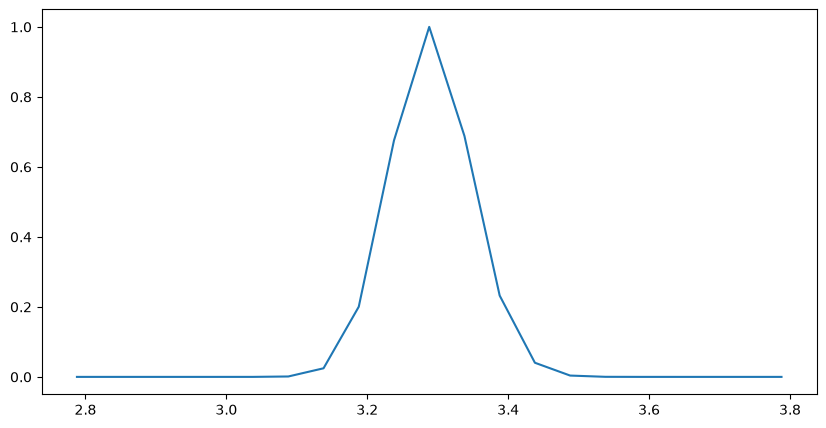

2D Search (Tau) for Part 9: 0it [00:00, ?it/s]

3.0879291852529143 is a good enough tau
3.1379291852529145 is a good enough tau
3.1879291852529144 is a good enough tau
3.2379291852529146 is a good enough tau
3.2879291852529144 is a good enough tau
3.3379291852529143 is a good enough tau
3.3879291852529145 is a good enough tau
3.4379291852529144 is a good enough tau
3.4879291852529146 is a good enough tau
Part 9 has a 0.0000 probability of bifurcation.
Part 9 has a 0.6196 metastability score.
part 10 lets go, best model is NonLinear1, but we'll do ModulatedGain anyway


/home/thardy/soundmodelenv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/thardy/soundmodelenv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/thardy/soundmodelenv/lib/pyt

Max threshold: 0.98
Fitted threshold from parent model: 2.00


Tau grid for part 10:   0%|          | 0/21 [00:00<?, ?it/s]

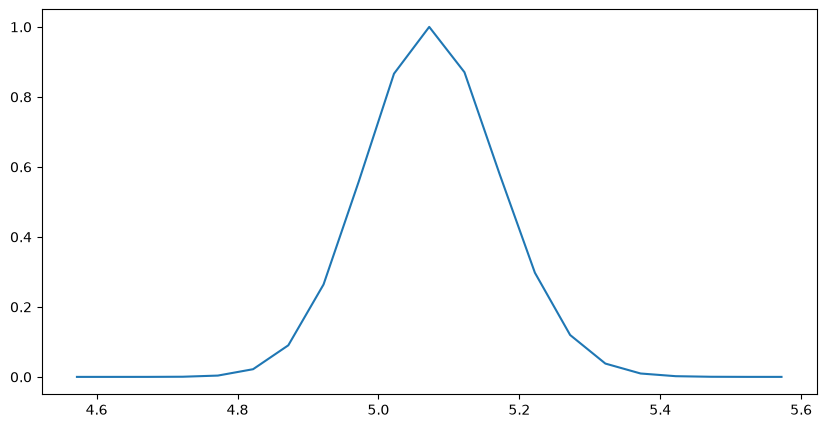

2D Search (Tau) for Part 10: 0it [00:00, ?it/s]

4.772092721661957 is a good enough tau
4.8220927216619565 is a good enough tau
4.872092721661956 is a good enough tau
4.922092721661956 is a good enough tau
4.972092721661957 is a good enough tau
5.022092721661957 is a good enough tau
5.0720927216619565 is a good enough tau
5.122092721661956 is a good enough tau
5.172092721661956 is a good enough tau
5.222092721661957 is a good enough tau
5.272092721661957 is a good enough tau
5.3220927216619565 is a good enough tau
5.372092721661956 is a good enough tau
5.422092721661956 is a good enough tau
Part 10 has a 0.0000 probability of bifurcation.
Part 10 has a 0.0000 metastability score.
part 11 lets go, best model is NonLinear1, but we'll do ModulatedGain anyway


/home/thardy/soundmodelenv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/thardy/soundmodelenv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/thardy/soundmodelenv/lib/pyt

Max threshold: 1.29
Fitted threshold from parent model: 0.54


Tau grid for part 11:   0%|          | 0/21 [00:00<?, ?it/s]

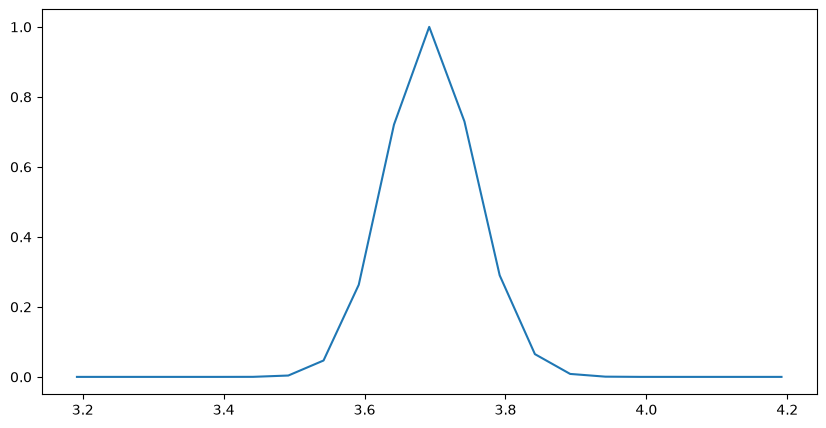

2D Search (Tau) for Part 11: 0it [00:00, ?it/s]

3.4917778114089852 is a good enough tau
3.5417778114089855 is a good enough tau
3.5917778114089853 is a good enough tau
3.6417778114089856 is a good enough tau
3.6917778114089854 is a good enough tau
3.7417778114089852 is a good enough tau
3.7917778114089855 is a good enough tau
3.8417778114089853 is a good enough tau
3.8917778114089856 is a good enough tau
Part 11 has a 0.0000 probability of bifurcation.
Part 11 has a 0.9496 metastability score.
part 12 lets go, best model is NonLinear1, but we'll do ModulatedGain anyway


/home/thardy/soundmodelenv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/thardy/soundmodelenv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/thardy/soundmodelenv/lib/pyt

Max threshold: 1.22
Fitted threshold from parent model: 1.99


Tau grid for part 12:   0%|          | 0/21 [00:00<?, ?it/s]

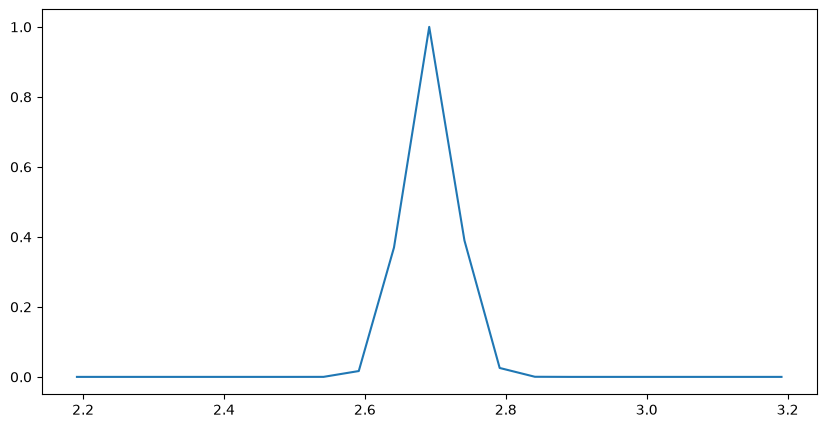

2D Search (Tau) for Part 12: 0it [00:00, ?it/s]

2.5913468371009607 is a good enough tau
2.641346837100961 is a good enough tau
2.691346837100961 is a good enough tau
2.741346837100961 is a good enough tau
2.791346837100961 is a good enough tau
Part 12 has a 0.0000 probability of bifurcation.
Part 12 has a 0.6409 metastability score.
part 13 lets go, best model is GainModulation, but we'll do ModulatedGain anyway


/home/thardy/soundmodelenv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/thardy/soundmodelenv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/thardy/soundmodelenv/lib/pyt

Max threshold: 1.34
Fitted threshold from parent model: 0.62


Tau grid for part 13:   0%|          | 0/21 [00:00<?, ?it/s]

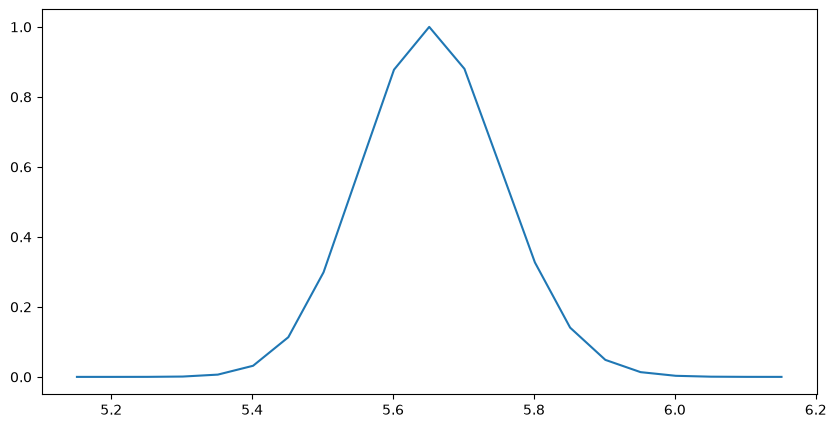

2D Search (Tau) for Part 13: 0it [00:00, ?it/s]

5.351342754320438 is a good enough tau
5.401342754320438 is a good enough tau
5.451342754320438 is a good enough tau
5.501342754320437 is a good enough tau
5.551342754320438 is a good enough tau
5.601342754320438 is a good enough tau
5.651342754320438 is a good enough tau
5.701342754320438 is a good enough tau
5.751342754320438 is a good enough tau
5.801342754320438 is a good enough tau
5.851342754320438 is a good enough tau
5.901342754320438 is a good enough tau
5.951342754320438 is a good enough tau
6.001342754320438 is a good enough tau
Part 13 has a 0.9933 probability of bifurcation.
Part 13 has a 1.0000 metastability score.
part 14 lets go, best model is GainModulation, but we'll do ModulatedGain anyway


/home/thardy/soundmodelenv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/thardy/soundmodelenv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/thardy/soundmodelenv/lib/pyt

Max threshold: 1.30
Fitted threshold from parent model: 1.03


Tau grid for part 14:   0%|          | 0/21 [00:00<?, ?it/s]

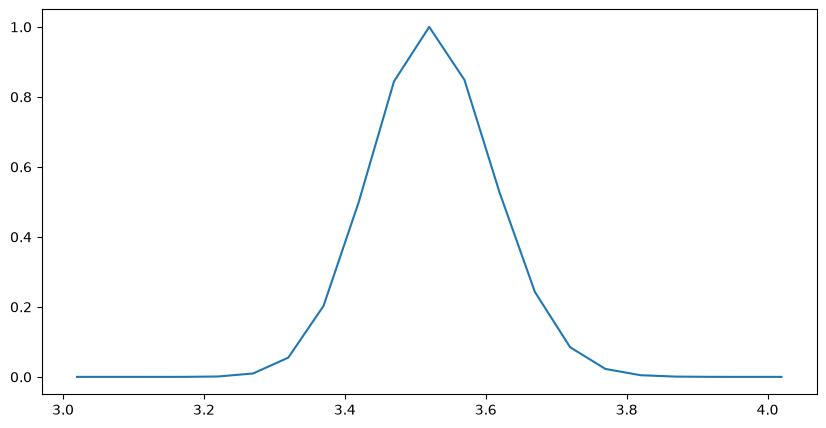

2D Search (Tau) for Part 14: 0it [00:00, ?it/s]

3.219825705904503 is a good enough tau
3.269825705904503 is a good enough tau
3.3198257059045027 is a good enough tau
3.369825705904503 is a good enough tau
3.4198257059045027 is a good enough tau
3.469825705904503 is a good enough tau
3.519825705904503 is a good enough tau
3.5698257059045027 is a good enough tau
3.619825705904503 is a good enough tau
3.6698257059045027 is a good enough tau
3.719825705904503 is a good enough tau
3.769825705904503 is a good enough tau
3.8198257059045027 is a good enough tau
Part 14 has a 0.9995 probability of bifurcation.
Part 14 has a 1.0000 metastability score.
part 15 lets go, best model is NonLinear1, but we'll do ModulatedGain anyway


/home/thardy/soundmodelenv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/thardy/soundmodelenv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/thardy/soundmodelenv/lib/pyt

Max threshold: 1.33
Fitted threshold from parent model: 0.41


Tau grid for part 15:   0%|          | 0/21 [00:00<?, ?it/s]

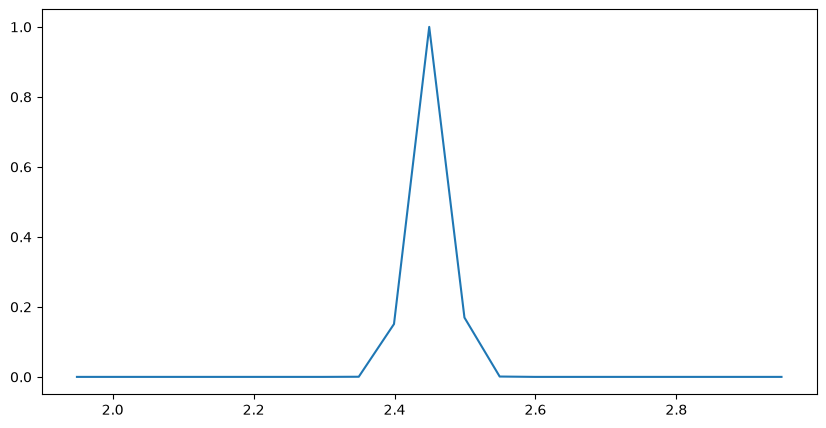

2D Search (Tau) for Part 15: 0it [00:00, ?it/s]

2.399264533809709 is a good enough tau
2.4492645338097088 is a good enough tau
2.4992645338097086 is a good enough tau
2.549264533809709 is a good enough tau
Part 15 has a 0.0000 probability of bifurcation.
Part 15 has a 0.6268 metastability score.
part 16 lets go, best model is GainModulation, but we'll do ModulatedGain anyway


/home/thardy/soundmodelenv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/thardy/soundmodelenv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/thardy/soundmodelenv/lib/pyt

Max threshold: 1.21
Fitted threshold from parent model: 0.56


Tau grid for part 16:   0%|          | 0/21 [00:00<?, ?it/s]

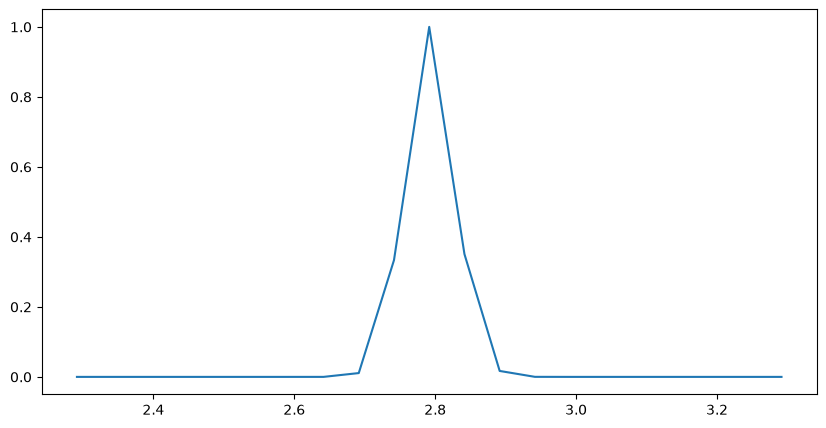

2D Search (Tau) for Part 16: 0it [00:00, ?it/s]

2.6915426608710984 is a good enough tau
2.7415426608710987 is a good enough tau
2.7915426608710985 is a good enough tau
2.8415426608710987 is a good enough tau
2.8915426608710986 is a good enough tau
Part 16 has a 0.0000 probability of bifurcation.
Part 16 has a 0.9186 metastability score.
part 17 lets go, best model is NonLinear1, but we'll do ModulatedGain anyway


/home/thardy/soundmodelenv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/thardy/soundmodelenv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/thardy/soundmodelenv/lib/pyt

Max threshold: 1.20
Fitted threshold from parent model: 1.98


Tau grid for part 17:   0%|          | 0/21 [00:00<?, ?it/s]

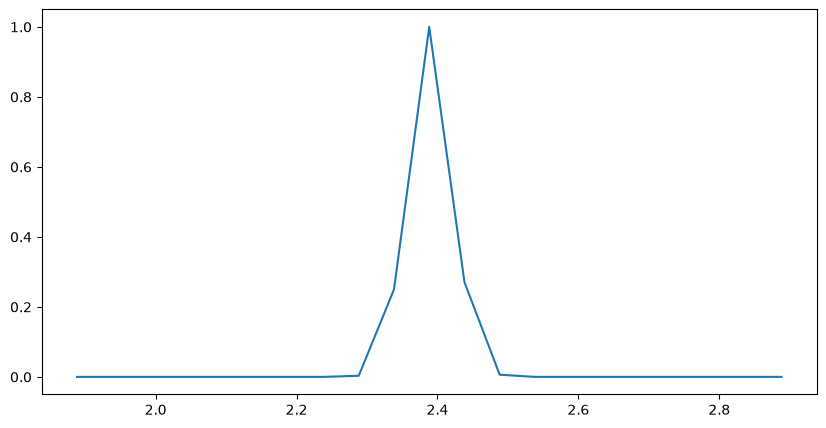

2D Search (Tau) for Part 17: 0it [00:00, ?it/s]

2.2883289204271304 is a good enough tau
2.3383289204271307 is a good enough tau
2.3883289204271305 is a good enough tau
2.4383289204271303 is a good enough tau
2.4883289204271306 is a good enough tau
Part 17 has a 0.0000 probability of bifurcation.
Part 17 has a 0.7851 metastability score.
part 18 lets go, best model is NonLinear1, but we'll do ModulatedGain anyway


/home/thardy/soundmodelenv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/thardy/soundmodelenv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/thardy/soundmodelenv/lib/pyt

Max threshold: 1.29
Fitted threshold from parent model: 1.07


Tau grid for part 18:   0%|          | 0/21 [00:00<?, ?it/s]

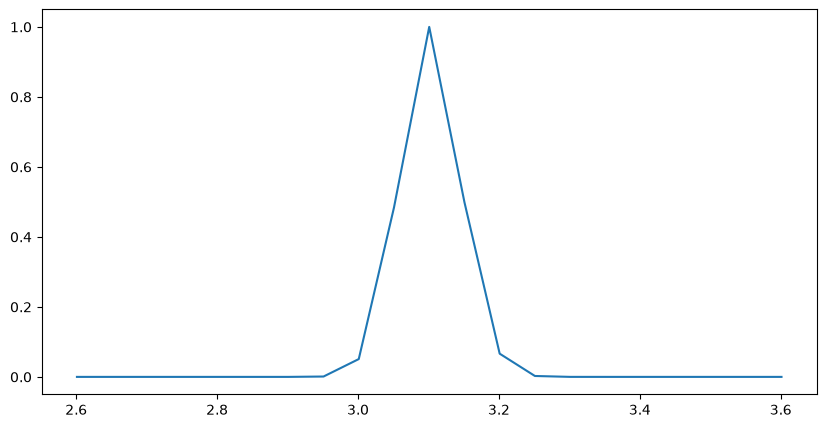

2D Search (Tau) for Part 18: 0it [00:00, ?it/s]

2.951111641332198 is a good enough tau
3.001111641332198 is a good enough tau
3.051111641332198 is a good enough tau
3.101111641332198 is a good enough tau
3.1511116413321982 is a good enough tau
3.201111641332198 is a good enough tau
3.251111641332198 is a good enough tau
Part 18 has a 0.0000 probability of bifurcation.
Part 18 has a 0.8664 metastability score.
part 19 lets go, best model is GainModulation, but we'll do ModulatedGain anyway


/home/thardy/soundmodelenv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/thardy/soundmodelenv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/thardy/soundmodelenv/lib/pyt

Max threshold: 1.24
Fitted threshold from parent model: 0.47


Tau grid for part 19:   0%|          | 0/21 [00:00<?, ?it/s]

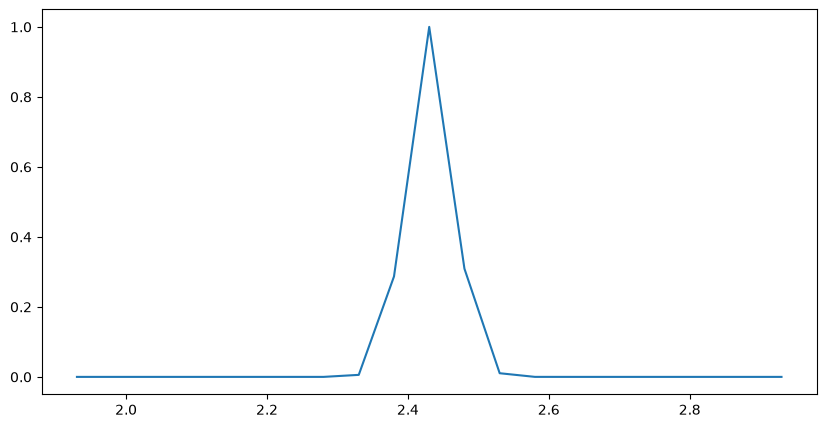

2D Search (Tau) for Part 19: 0it [00:00, ?it/s]

2.330295976433116 is a good enough tau
2.3802959764331164 is a good enough tau
2.4302959764331162 is a good enough tau
2.4802959764331165 is a good enough tau
2.5302959764331163 is a good enough tau
Part 19 has a 0.0000 probability of bifurcation.
Part 19 has a 0.9173 metastability score.


In [6]:
task = "Active"
period = "early"
file_path = Path(f'Fit_{task}_{period}')
sub_file_path = "MetaBifurc_ModulatedGain_21^2"

# Define the summary path clearly and load existing progress 
summary_path = file_path / sub_file_path / "metabifurc.csv"
if summary_path.exists():
    print(f"Found existing summary at {summary_path}. Loading progress...")
    existing_df = pd.read_csv(summary_path, index_col=0)
    bifurcation_prob = existing_df["probability_of_bifurcation"].to_dict()
    metastability_scores = existing_df["metastability_score"].to_dict()
    print(bifurcation_prob)
    print(metastability_scores)
else:
    bifurcation_prob, metastability_scores = {}, {}

# load the name of the best model for each participant
json_path = cwd / f"5CV_{task}_{period}.json"
with open(json_path, "r") as f:
    data_5cv = json.load(f)
    results_cv = data_5cv.get("results_cv")
    print("Loaded results_cv:", results_cv)

    
for part in range(20):
    best_model = results_cv[part]
    print(f'part {part} lets go, best model is {best_model}, but we\'ll do ModulatedGain anyway')
    
    # --- SKIP if already processed --- 
    if part in bifurcation_prob:
        print(f">>> Part {part} already exists in CSV. Skipping...")
        continue
    
    # --- Load Data ---
    data_ref = f'myEpochs_{task}/Epoch_{SubIDs[part]}-epo.fif'
    epochs_file = cwd.parents[0] / data_ref
    
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", category=RuntimeWarning)
        state_train = lead.STG(epochs_file, tmin=100, tmax=200)
        n_categories = len(list(state_train.keys()))
        categories = list(range(n_categories))

    # --- Input Definition ---
    one_input = np.concatenate((np.zeros(60), np.ones(10), np.zeros(180)))
    input_train = {cat: np.stack([one_input for _ in range(state_train[cat].shape[0])]) for cat in categories}

    # --- Data Reformating ---
    state_train_constant_stim = {cat: state_train[cat][:,60:70] for cat in range(1, n_categories)}
    input_train_constant_stim = {cat: input_train[cat][:,60:70] for cat in range(1, n_categories)}
    no_stim_sliced = np.concatenate([state_train[0][:, i*50:(i+1)*50] for i in range(5)])
    pre_stim_sliced = np.concatenate([state_train[cat][:, :50] for cat in range(1, n_categories)])
    state_train_constant_stim[0] = np.concatenate((no_stim_sliced, pre_stim_sliced))
    input_train_constant_stim[0] = np.zeros_like(state_train_constant_stim[0])

    # --- Define upper bound for threshold parameter ---
    max_threshold = np.percentile(state_train[n_categories-1], 90)
    print(f"Max threshold: {max_threshold:.2f}")

    ########## ONLY MODULATED GAIN ######################
    
    # --- Load Parent Parameters ---
    gainmodul_parent = lead.model.StratifiedGainModulation(
        tau=10, process_noise=0.1, measure_noise=0.1, threshold=1, sharpness=5)
    param_path = file_path / f"GainModulatedModel_part{part}_params"
    gainmodul_parent.load_params(param_path)
    print(f"Fitted threshold from parent model: {gainmodul_parent.threshold:.2f}")


    # --- Define Ranges ---
    thresh_range = np.linspace(0, 2, 21)
    if gainmodul_parent.tau < 2:
        tau_range = np.linspace(1.5, 2.5, 21)
    else:
        tau_range = np.linspace(gainmodul_parent.tau - 0.5, gainmodul_parent.tau + 0.5, 21)

    
    # --- Step 1: Grid Search for Tau (to fix input params for the next step) ---
    
    ll_list_tau, params_through_tau = [], []
    for tau in tqdm(tau_range, desc=f"Tau grid for part {part}"):
        linear_resting_state = lead.model.StratifiedLinear(tau=tau, process_noise=0.1, measure_noise=0.1, w0=0)
        
        linear_resting_state.fit(
            state_series={0: state_train_constant_stim[0]},
            input_series={0: input_train_constant_stim[0]},
            init_params=[tau, 0.1, 0.1] + [0]*7,
            bounds=[(1, 25), (0.01, 1), (0.01, 1)] + [(0, 1)]*7,
            fixed_params=['tau'] + [f'w{i}' for i in range(7)])
        
        ll_list_tau.append(linear_resting_state.loglikelihood({0: state_train_constant_stim[0]}, {0: input_train_constant_stim[0]}))
        params_through_tau.append([linear_resting_state.tau, linear_resting_state.process_noise, linear_resting_state.measure_noise])

    # Plot the distrib for visual check
    ll_array_tau = np.array(ll_list_tau)
    likelihood_tau = np.exp(ll_array_tau - np.max(ll_array_tau))
    plt.figure(figsize=(10,5))
    plt.plot(tau_range, likelihood_tau)
    plt.show()


    # --- Step 2: 2D Grid Search (Tau vs Threshold) ---
    bif_array, meta_array = np.zeros((len(tau_range), len(thresh_range))), np.zeros((len(tau_range), len(thresh_range)))
    ll_array = -np.inf*np.ones((len(tau_range), len(thresh_range)))

    # We iterate through the params found in Step 1
    for idx_tau, [tau, process_noise, measure_noise] in tqdm(enumerate(params_through_tau), desc=f"2D Search (Tau) for Part {part}"):

        # When tau is too unlikely, keep the default ll = -np.inf and bif = meta = 0 (no bifurcation)
        if likelihood_tau[idx_tau] < 0.001:
            continue
        print(f'{tau} is a good enough tau')

        ll_this_tau = ll_list_tau[idx_tau]

        # Inner loop over threshold
        for idx_th, threshold in enumerate(thresh_range):

            # When threshold is too high compared to data, keep the default ll = -np.inf and bif = meta = 0
            if threshold > max_threshold:
                continue
            
            # A. Fit gain and input_weight for this specific (tau, threshold) combo
            ll_local = 0
            # Initialize base model for this grid point
            gainmodul = lead.model.StratifiedGainModulation(
                tau=tau, process_noise=process_noise, measure_noise=measure_noise, 
                threshold=threshold, sharpness=5)
            
            for cat in range(1, n_categories):
                # Retrieve parent weights
                w_parent = getattr(gainmodul_parent, f'w{cat}')
                g_parent = getattr(gainmodul_parent, f'g{cat}')
                
                gainmodul_one_cat = lead.model.GainModulation(
                    tau=tau, process_noise=process_noise, measure_noise=measure_noise, 
                    threshold=threshold, sharpness=5, 
                    input_weight=w_parent, gain=g_parent)
                
                # Fit specific category
                gainmodul_one_cat.fit(
                    state_series={0: state_train_constant_stim[cat]},
                    input_series={0: input_train_constant_stim[cat]},
                    init_params=[getattr(gainmodul_one_cat, pname) for pname in gainmodul_one_cat._param_names],
                    bounds=[(1,25), (0.01, 1), (0.01, 1), (0, 1), (0, 1), (0, 2), (0, 10)],
                    fixed_params=['tau', 'process_noise', 'measure_noise', 'threshold', 'sharpness'])
                
                ll_local += gainmodul_one_cat.loglikelihood({0: state_train_constant_stim[cat]}, {0: input_train_constant_stim[cat]})
                
                # Update the main stratified model with fitted params
                gainmodul.set_params({f'w{cat}': gainmodul_one_cat.input_weight, f'g{cat}': gainmodul_one_cat.gain})
            
            ll_array[idx_tau, idx_th] = ll_this_tau + ll_local
            
            # B. Assess bifurcation and metastability (Linear Interpolation)
            states = np.linspace(-0.5, 3, 1000)
            delta_x_list = []
            max_metascore = 0
            
            for cat in range(n_categories - 1):
                # Initial state diff
                delta_x_list.append(gainmodul.core(state=states, input_value=1, signal_category=cat) - states)
                
                w1, g1 = getattr(gainmodul, f'w{cat}'), getattr(gainmodul, f'g{cat}')
                w2, g2 = getattr(gainmodul, f'w{cat+1}'), getattr(gainmodul, f'g{cat+1}')
                
                # Travel on the (w1, g1) -> (w2, g2) segment 
                for t in np.linspace(0, 1, 100):
                    w, g = w1 + t*(w2-w1), g1 + t*(g2-g1)
                    
                    interp_model = lead.model.GainModulation(
                        tau=tau, process_noise=process_noise, measure_noise=measure_noise, 
                        threshold=threshold, sharpness=5, 
                        input_weight=w, gain=g
                    )

                    # Prepare for metastability score calculation
                    model_func = interp_model.core
                    def f(states, input_value=0, signal_category=cat):
                        return model_func(states, input_value * np.ones_like(states), signal_category) - states
                    def df(states, input_value=0, signal_category=cat):
                        epsilon = 1e-5
                        return (f(states + epsilon, input_value, signal_category) - f(states - epsilon, input_value, signal_category)) / (2*epsilon)
        
                    # Compute metastability score
                    metascore = metastability_score(lambda x: f(x, input_value=1, signal_category=cat), 
                                                    lambda x: df(x, input_value=1, signal_category=cat), 
                                                    states, tau=tau)
                    max_metascore = max(max_metascore, metascore)

                    # Prepare for bifurcation check
                    delta_x_list.append(interp_model.core(state=states, input_value=1, signal_category=0) - states)

            # Compute bifurcation check
            bifbool = is_bifurcation(delta_x_list)
            bif_array[idx_tau, idx_th] = int(bifbool)
            meta_array[idx_tau, idx_th] = max_metascore

    ########## ONLY MODULATED GAIN ######################


    if best_model == 'Linear':
        bif_array, meta_array = np.zeros((20, 20)), np.zeros((20, 20))
        ll_array = -np.ones((20, 20))


    # --- Process Results ---
    likelihood = np.exp(ll_array - np.max(ll_array))

    # Save Results
    os.makedirs(file_path / sub_file_path, exist_ok=True)
    np.savez(file_path / sub_file_path / f"2D_grid_search_part{part}.npz", threshold_range=thresh_range, tau_range=tau_range, ll=ll_array, likelihood=likelihood, bifbool=bif_array, metascore=meta_array)

    # Weighting BifProb and MetaScore over the 2D surface)
    bifprob = np.average(bif_array, weights=likelihood)
    metascore = np.average(meta_array, weights=likelihood)
    bifurcation_prob[part], metastability_scores[part] = bifprob, metascore
    print(f'Part {part} has a {bifprob:.4f} probability of bifurcation.')
    print(f'Part {part} has a {metascore:.4f} metastability score.')

    # Save summary CSV
    df_bifprob = pd.DataFrame.from_dict(
        bifurcation_prob, orient="index", columns=["probability_of_bifurcation"]
    ).sort_index()
    df_metascore = pd.DataFrame.from_dict(
        metastability_scores, orient="index", columns=["metastability_score"]
    ).sort_index()
    df = pd.concat([df_bifprob, df_metascore], axis=1)
    df.to_csv(file_path / sub_file_path / "metabifurc.csv")

    # --- 3. Plotting (2D Heatmap with Contours) ---
    plt.figure(figsize=(10, 8))
    
    # Create 2D Meshgrid for plotting
    # thresh_range (x-axis), tau_range (y-axis)
    X, Y = np.meshgrid(thresh_range, tau_range)
    
    # 1. Plot Heatmap of Likelihood
    # Using pcolormesh for the heatmap
    pcm = plt.pcolormesh(X, Y, likelihood, shading='auto', cmap='viridis')
    plt.colorbar(pcm, label='Relative Likelihood')
    
    # 2. Plot Contour of Bifurcation Boundary
    # We draw a line at 0.5 (since bif_array is 0 or 1) to show the border
    # colors='red' makes the bifurcation line distinct
    if np.any(bif_array) and not np.all(bif_array):
        CS = plt.contour(X, Y, bif_array, levels=[0.5], colors='red', linewidths=2)
        # Create a proxy artist for the legend
        from matplotlib.lines import Line2D
        proxy_line = Line2D([0], [0], color='red', linewidth=2, label='Bifurcation Boundary')
        plt.legend(handles=[proxy_line], loc='upper right')
    elif np.all(bif_array):
        plt.title(f"Part {part} (All Bifurcation)")
    else:
        plt.title(f"Part {part} (No Bifurcation)")

    plt.title(f'Parameter Space: Tau vs Threshold - Part {part}\nWeighted Bifurcation Prob: {bifprob:.3f}')
    plt.xlabel('Threshold')
    plt.ylabel('Tau')
    
    # Save plot
    plt.savefig(file_path / sub_file_path / f"2D_likelihood_part{part}_{task}.png")
    plt.close()